# 03 - Dataset III synthesis (milestone 4)

`PROJECT_PLAN.md` §9.2-9.3 steps 1-5: rank-1 base TRFs from the milestone-3
long-term TRFs, X_L / X_R from a noise subject's attended envelopes, the
time-reversed 128 Hz EEG of that subject as noise, and SNR scaling. Needs
`results/section_a/long_term_trf.npz` (notebook 02 with `SAVE = True`, or
`scripts/05_long_term_trf.py`). Same code as
`scripts/06_synthesize_dataset3.py` (`adr.synth.check`).

Set A noise subjects only; nothing is tuned or frozen here.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adr.config import load_paths, package_versions, seed_everything

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
pd.set_option("display.max_columns", 50, "display.width", 200)
paths = load_paths()
seed_everything()
package_versions()

{'python': '3.14.8',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'pandas': '3.0.6',
 'mne': '1.13.2',
 'scikit-learn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.2',
 'eelbrain': '0.43.0b0',
 'matplotlib': '3.11.2',
 'mne-icalabel': '0.10.0'}

In [2]:
from adr.synth import check
from adr.synth import dataset3 as d3

split = d3.load_noise_split()
print("Set A:", split["set_a"]); print("Set B:", split["set_b"])
SUBJECT = split["set_a"][0]
base, lags, names = d3.load_base_trfs()

Set A: ['S4', 'S5', 'S6', 'S7', 'S8', 'S10', 'S11', 'S14']
Set B: ['S1', 'S2', 'S3', 'S9', 'S12', 'S13', 'S15', 'S16']


## One synthetic recording

Clean signal (X, scaled to the target SNR) and the synthetic EEG (X + noise)
at one channel, in the analysis space (Cz reference, 1-9 Hz).

noise subject S4: 38.4 min, achieved SNR -10.00 dB


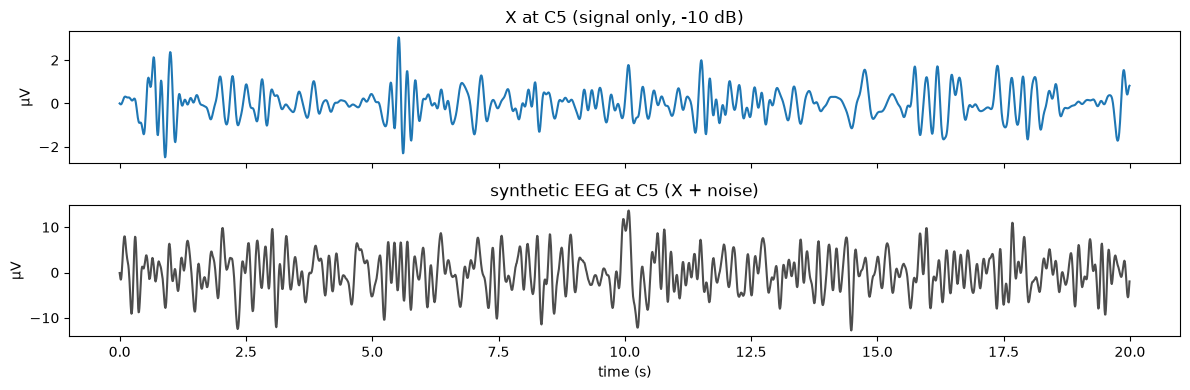

In [3]:
SNR_DB = -10
source = d3.noise_source(SUBJECT)
rec = d3.synthesize(source, "L", SNR_DB, base, lags)
print(f"noise subject {SUBJECT}: {len(rec.eeg) / 128 / 60:.1f} min, achieved SNR {d3.snr_db(rec.clean, rec.eeg - rec.clean):.2f} dB")
clean, noisy = d3.analysis_space(rec.clean), d3.analysis_space(rec.eeg)
ch = names.index("C5")
t = np.arange(128 * 20) / 128
fig, ax = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
ax[0].plot(t, clean[: len(t), ch] * 1e6); ax[0].set_title(f"X at C5 (signal only, {SNR_DB} dB)"); ax[0].set_ylabel("µV")
ax[1].plot(t, noisy[: len(t), ch] * 1e6, color="0.3"); ax[1].set_title("synthetic EEG at C5 (X + noise)"); ax[1].set_ylabel("µV")
ax[1].set_xlabel("time (s)"); fig.tight_layout()

## Recovery across SNRs

Relative MSE (Das et al. Eq. 14-15) of TRFs estimated from the synthetic EEG
against the base TRF: long-term (whole recording) and median over the
120 s trials with lambda 0.2 vs the Das rule (open item 11).

In [4]:
table = check.run(SUBJECT)
table.round(3)

S4 SNR  +0.0 (achieved  +0.00) L: long-term 0.138 | 120 s median: lambda 0.2 0.292, Das 0.147


S4 SNR  +0.0 (achieved  +0.00) R: long-term 0.147 | 120 s median: lambda 0.2 0.345, Das 0.151


S4 SNR  -5.0 (achieved  -5.00) L: long-term 0.109 | 120 s median: lambda 0.2 0.310, Das 0.120


S4 SNR  -5.0 (achieved  -5.00) R: long-term 0.114 | 120 s median: lambda 0.2 0.349, Das 0.123


S4 SNR -10.0 (achieved -10.00) L: long-term 0.099 | 120 s median: lambda 0.2 0.422, Das 0.125


...

S4 SNR -20.0 (achieved -20.00) L: long-term 0.119 | 120 s median: lambda 0.2 0.837, Das 0.260


S4 SNR -20.0 (achieved -20.00) R: long-term 0.121 | 120 s median: lambda 0.2 0.835, Das 0.276


S4 SNR -25.0 (achieved -25.00) L: long-term 0.157 | 120 s median: lambda 0.2 0.943, Das 0.477


S4 SNR -25.0 (achieved -25.00) R: long-term 0.154 | 120 s median: lambda 0.2 0.945, Das 0.466


,subject,snr_db,condition,achieved_snr_db,long_term,short_0.2,short_das,n_trials
0,S4,0,L,0.0,0.138,0.292,0.147,19
1,S4,0,R,0.0,0.147,0.345,0.151,19
2,S4,-5,L,-5.0,0.109,0.310,0.120,19
3,S4,-5,R,-5.0,0.114,0.349,0.123,19
4,S4,-10,L,-10.0,0.099,0.422,0.125,19
5,S4,-10,R,-10.0,0.105,0.443,0.128,19
6,S4,-15,L,-15.0,0.104,0.631,0.160,19
7,S4,-15,R,-15.0,0.108,0.648,0.173,19
8,S4,-20,L,-20.0,0.119,0.837,0.260,19
9,S4,-20,R,-20.0,0.121,0.835,0.276,19


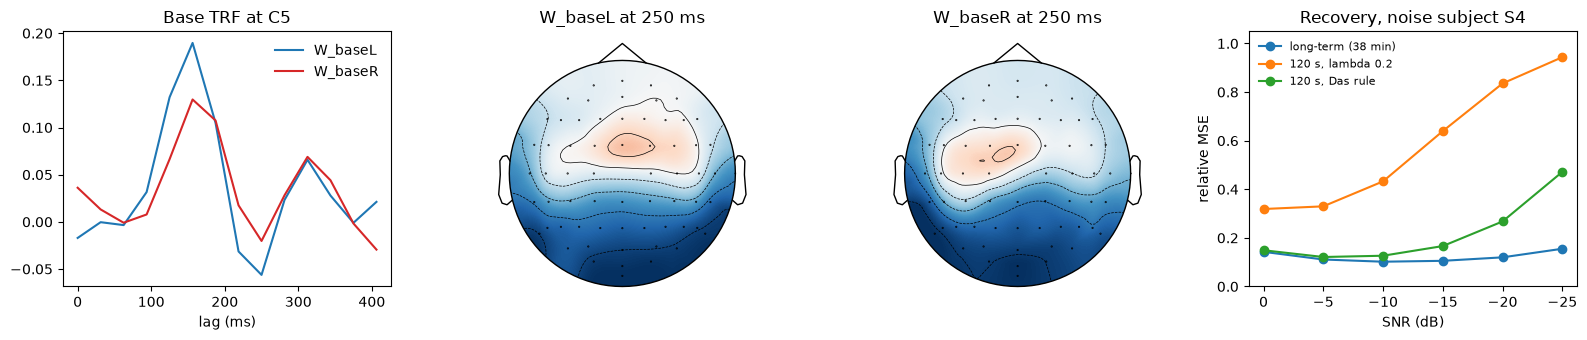

In [5]:
fig = check.plot(table)